# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot PSL and wind vector composites by node over all times

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import dask

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

## Load training data to interpret SOMs

In [3]:
# set input directory
dir_in = dir_base + 'som_training/'

In [4]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [5]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Set the parameter combinations for SOM finalists

In [6]:
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3, 4]    # (y-axis)
som_grid_cols    = [3, 4]    # (x-axis)
ranks            = [3, 45]
sigs             = [1.0, 1.0]
lrs              = [0.01, 0.005]
nitrs            = [250000, 50000]

## MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
n = 0

In [7]:
# select info for input file (set above)
som_row = som_grid_rows[n]
som_col = som_grid_cols[n]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [8]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

som_alaska_psl_3x3_sig1.0_lr0.01_iter250000


## Load pickles of "winning" combos and make assessment plots

In [9]:
# open pickle
with open(dir_in+'pickles/psl_som/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [10]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.348131518266264


In [11]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [12]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


## Load data to make composites
- not identical to training data so we can see larger area patterns
- Need PSL, UBOT, VBOT

In [13]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

In [14]:
# Load PSL
var_in = 'PSL'

# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_decadal_alaska_cam_grid'
# load data
ds = xr.open_mfdataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
#ds = ds.load()

# need to stack the data in the "time" dimension so that it matches training data - stacking all dates (ntimes = ensemble x decades x autumn days)
# stack all times into a single array
ds_all_times = ds.stack(time=("ensemble","decades","autumn_days"))

# save just psl and convert to hPa from Pa
ds_all_times = ds_all_times[var_in]/100.0
#ds_all_times = ds_all_times.PSL/100.0

# calculate daily PSL anomalies for composites too
# Calculate spatial mean
means = ds_all_times.mean(dim=['lat','lon'])

# get spatial anomalies
ds_all_times_anom = ds_all_times - means

# explicitly load data so that it doesn't take forever later on during mean
psl_all_times_anom = ds_all_times_anom.load()

In [15]:
# Load UBOT
var_in = 'UBOT'

# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_decadal_alaska_cam_grid'
# load data
ds = xr.open_mfdataset(dir_in+fin_training+'.nc')

# need to stack the data in the "time" dimension so that it matches training data - stacking all dates (ntimes = ensemble x decades x autumn days)
# stack all times into a single array
ds_all_times = ds.stack(time=("ensemble","decades","autumn_days"))

# save just UBOT
ds_all_times = ds_all_times[var_in]

# explicitly load data so that it doesn't take forever later on during mean
ubot_all_times = ds_all_times.load()

In [16]:
# Load UBOT
var_in = 'VBOT'

# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_decadal_alaska_cam_grid'
# load data
ds = xr.open_mfdataset(dir_in+fin_training+'.nc')

# need to stack the data in the "time" dimension so that it matches training data - stacking all dates (ntimes = ensemble x decades x autumn days)
# stack all times into a single array
ds_all_times = ds.stack(time=("ensemble","decades","autumn_days"))

# save just UBOT
ds_all_times = ds_all_times[var_in]

# explicitly load data so that it doesn't take forever later on during mean
vbot_all_times = ds_all_times.load()

## Break Data into decades

In [17]:
# set lat and lon
lat = ds.lat
lon = ds.lon

In [18]:
nodes = list(range(0,len(som_keys),1))

In [19]:
# get all training times
all_times = subset.training_times
all_yy = all_times.decades
# all_dd = all_times.autumn_days - this is the DOY from Sept.1 (0) to Dec.31 (365)

In [20]:
# make numpy arrays to fill with frequencies
psl_all = np.zeros([len(nodes),len(lat),len(lon)])
ubot_all = np.zeros([len(nodes),len(lat),len(lon)])
vbot_all = np.zeros([len(nodes),len(lat),len(lon)])

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
#for map_num in range(len(som_keys))[0:1]:
    # get indices of training data that mapped to this node
    inds = winmap[som_keys[map_num]]
    print(len(inds))
    # grab the compositing data that corresponds to those training times
    data = psl_all_times_anom
    with dask.config.set(**{'array.slicing.split_large_chunks': False}):
        ds_sub = data.isel(time=inds)      
    # grab data for the subset of years and average
    psl_all[map_num,:,:] = ds_sub.mean(dim="time", skipna=True).data
    # grab the compositing data that corresponds to those training times
    data = ubot_all_times
    with dask.config.set(**{'array.slicing.split_large_chunks': False}):
        ds_sub = data.isel(time=inds)      
    # grab data for the subset of years and average
    ubot_all[map_num,:,:] = ds_sub.mean(dim="time", skipna=True).data
    # grab the compositing data that corresponds to those training times
    data = vbot_all_times
    with dask.config.set(**{'array.slicing.split_large_chunks': False}):
        ds_sub = data.isel(time=inds)      
    # grab data for the subset of years and average
    vbot_all[map_num,:,:] = ds_sub.mean(dim="time", skipna=True).data

6064
5139
4252
7144
6622
6083
3896
5552
4658


In [21]:
print(psl_all.shape)

(9, 160, 240)


In [22]:
# convert the numpy array to a xarray and set coordinate arrays
psl_composite_all = xr.DataArray(psl_all,dims=('node','lat','lon'))
psl_composite_all['node'] = nodes
psl_composite_all['lat'] = lat
psl_composite_all['lon'] = lon

ubot_composite_all = xr.DataArray(ubot_all,dims=('node','lat','lon'))
ubot_composite_all['node'] = nodes
ubot_composite_all['lat'] = lat
ubot_composite_all['lon'] = lon

vbot_composite_all = xr.DataArray(vbot_all,dims=('node','lat','lon'))
vbot_composite_all['node'] = nodes
vbot_composite_all['lat'] = lat
vbot_composite_all['lon'] = lon

## Plot composite maps of psl anomaly across lattice

In [23]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'
fout = 'figure_2_som_alaska_'+str(som_row)+'x'+str(som_col)+'_PSLanom_wind_vectors_composite.png'
print(fout)

figure_2_som_alaska_3x3_PSLanom_wind_vectors_composite.png


In [24]:
## set colors
cmap_choice = plt.cm.get_cmap('coolwarm')

# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

# set plotting info
title = 'PSL'
units = 'hPa'
vmin_in = -28.0
vmax_in = 28.0 
levels_in = np.arange(vmin_in,vmax_in+2,2)
ticks_1 = levels_in
intv = 5

In [25]:
# set node names
node_names = ['0a', '0b', '0c', '1a', '1b', '1c', '2a', '2b', '2c']

### Plot anomalies over all time

node: 0
node: 1
node: 2
node: 3
node: 4
node: 5
node: 6
node: 7
node: 8


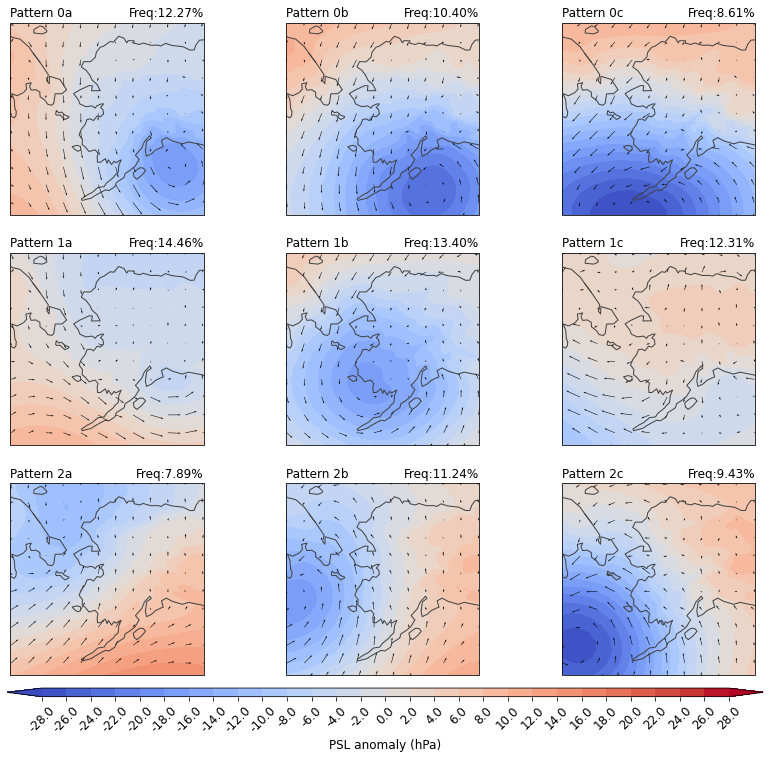

In [37]:
# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, subplot_kw={'projection':ccrs.Stereographic(central_longitude=lon_avg)}, figsize=(14,12))

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
    print('node: '+str(map_num))
    # grab the composite data that corresponds to those training times and node
    psl_sub = psl_composite_all.isel(node=map_num)
    ubot_sub = ubot_composite_all.isel(node=map_num)
    vbot_sub = vbot_composite_all.isel(node=map_num)

    # make plot for this node - note using .values converts from xarray to numpy array
    cs = axs[som_keys[map_num][0],som_keys[map_num][1]].contourf(lon, lat, psl_sub.values,
                                                                 levels=levels_in, extend='both', cmap=cmap_choice, transform=ccrs.PlateCarree())
    # add vectors
    vc = axs[som_keys[map_num][0],som_keys[map_num][1]].quiver(lon, lat, ubot_sub.values, vbot_sub.values,
                                                               regrid_shape=20, color='black',linewidth=1.0, transform=ccrs.PlateCarree())
    # modify the plots
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_extent([lon_min,lon_max,lat_min,lat_max])
    axs[som_keys[map_num][0],som_keys[map_num][1]].coastlines(resolution='110m', color='0.25', linewidth=1.0, zorder=10)
    
    # plot titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Pattern '+node_names[map_num], loc="left",fontsize=12)
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Freq:{:.2f}'.format(frequencies.flatten()[map_num])+'%', loc="right",fontsize=12)

# finalize figure 
#plt.suptitle('Alaska SOM node composite '+title+' anomaly - '+times, fontsize=12, x=0.515, y=0.925)

# colorbar stuff
cbar_ax = fig.add_axes([0.14,0.1,0.75,0.01]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:], orientation='horizontal')
cbar.ax.set_xticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=12,rotation=45)
cbar.set_label('PSL anomaly ('+units+')', fontsize=12)
# quiver key
#qk = axs.quiverkey(Q,0.85,0.025,10,r'10 '+units,labelpos='S', coordinates='axes',color='black',zorder=2)

# save figure
plt.savefig(fout, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+fout, bbox_inches='tight', dpi=200)